# 3. Fine-tuning BERT for News Classification

We fine-tune `bert-base-uncased` (Devlin et al., 2019) with a linear classification head on the AG News training split. Training runs for three epochs with AdamW (learning rate 2e-5, weight decay 0.01, 6% linear warm-up), batch size 32, maximum sequence length 128 and mixed precision. The checkpoint with the highest validation accuracy is restored and evaluated once on the official test split.

This notebook is self-contained and runs on Google Colab with a GPU runtime (Runtime > Change runtime type > T4 GPU).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EmpireNetwork123/explainable-news-classification/blob/main/notebooks/03_bert_finetune.ipynb)

## 3.1 Environment

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/explainable-news-classification").exists():
        !git clone -q https://github.com/EmpireNetwork123/explainable-news-classification.git /content/explainable-news-classification
    %cd /content/explainable-news-classification
    !pip install -q -r requirements.txt
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(ROOT)
sys.path.insert(0, os.getcwd())

/content/explainable-news-classification
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import torch, transformers

print("PyTorch", torch.__version__, "| Transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available")

PyTorch 2.11.0+cu130 | Transformers 5.20.2
GPU: Tesla T4


## 3.2 Data

In [3]:
from src import config
from src.download_data import download
from src.preprocess import preprocess_and_save

if not (config.RAW_DIR / "ag_news_train.csv").exists():
    download()
preprocess_and_save()

train: 120,000 rows -> data/raw/ag_news_train.csv
test: 7,600 rows -> data/raw/ag_news_test.csv
train: 108,000 rows -> data/processed/ag_news_clean_train.csv
val: 12,000 rows -> data/processed/ag_news_clean_val.csv
test: 7,600 rows -> data/processed/ag_news_clean_test.csv


## 3.3 Fine-tuning

In [4]:
!python -m src.train_bert

config.json: 100% 570/570 [00:00<00:00, 3.05MB/s]
tokenizer_config.json: 100% 48.0/48.0 [00:00<00:00, 307kB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 15.9MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 5.94MB/s]

model.safetensors: downloading bytes: 100% 415M/415M [00:02<00:00, 187MB/s, 37.7MB/s  ]
model.safetensors: reconstructing file: 100% 440M/440M [00:02<00:00, 198MB/s, 40.4MB/s  ]
Loading weights: 100% 199/199 [00:00<00:00, 5170.04it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     |
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |
cls.predictions.transform.dense.weight     | UNEXPECTED |
cls.seq_relationship.bias                  | UNEXPECTED |
cls.seq_relationship.weight                | UNEXPECTED |
cls.predictions.transform.dense.bias       | UNEXPECTED |
cl

## 3.4 Test-set evaluation

In [5]:
import json
import pandas as pd
from IPython.display import Image, display

metrics = json.loads((config.METRICS_DIR / "bert_metrics.json").read_text())
report = pd.DataFrame(metrics["per_class"]).T.loc[config.LABEL_NAMES + ["macro avg"], ["precision", "recall", "f1-score", "support"]]
print(f"Accuracy: {metrics['accuracy']:.4f}   Macro-F1: {metrics['macro_f1']:.4f}   ({metrics['device']})")
report.round(4)

Accuracy: 0.9422   Macro-F1: 0.9423   (Tesla T4)


,precision,recall,f1-score,support
World,0.9558,0.9453,0.9505,1900.0
Sports,0.9900,0.9895,0.9897,1900.0
Business,0.9138,0.9037,0.9087,1900.0
Sci/Tech,0.9099,0.9305,0.9201,1900.0
macro avg,0.9424,0.9422,0.9423,7600.0


In [6]:
log = json.loads((config.METRICS_DIR / "bert_log_history.json").read_text())
pd.DataFrame([e for e in log if "eval_loss" in e])[["epoch", "eval_loss", "eval_accuracy"]].round(4)

,epoch,eval_loss,eval_accuracy
0,1.0,0.1854,0.9356
1,2.0,0.1877,0.9401
2,3.0,0.1982,0.9423


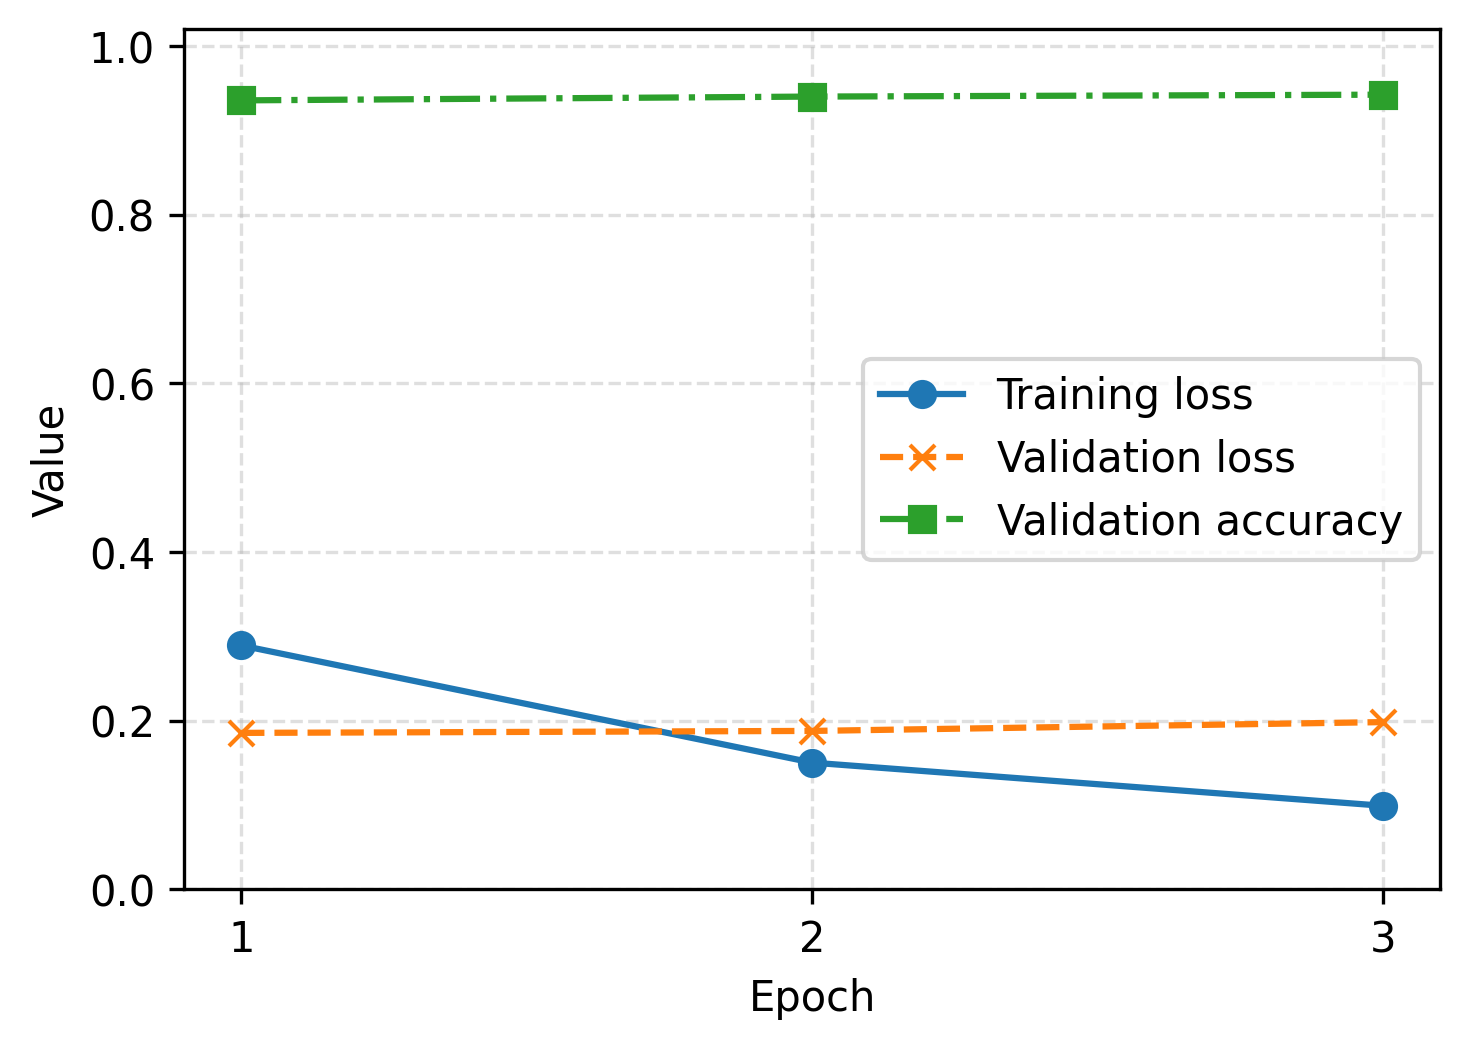

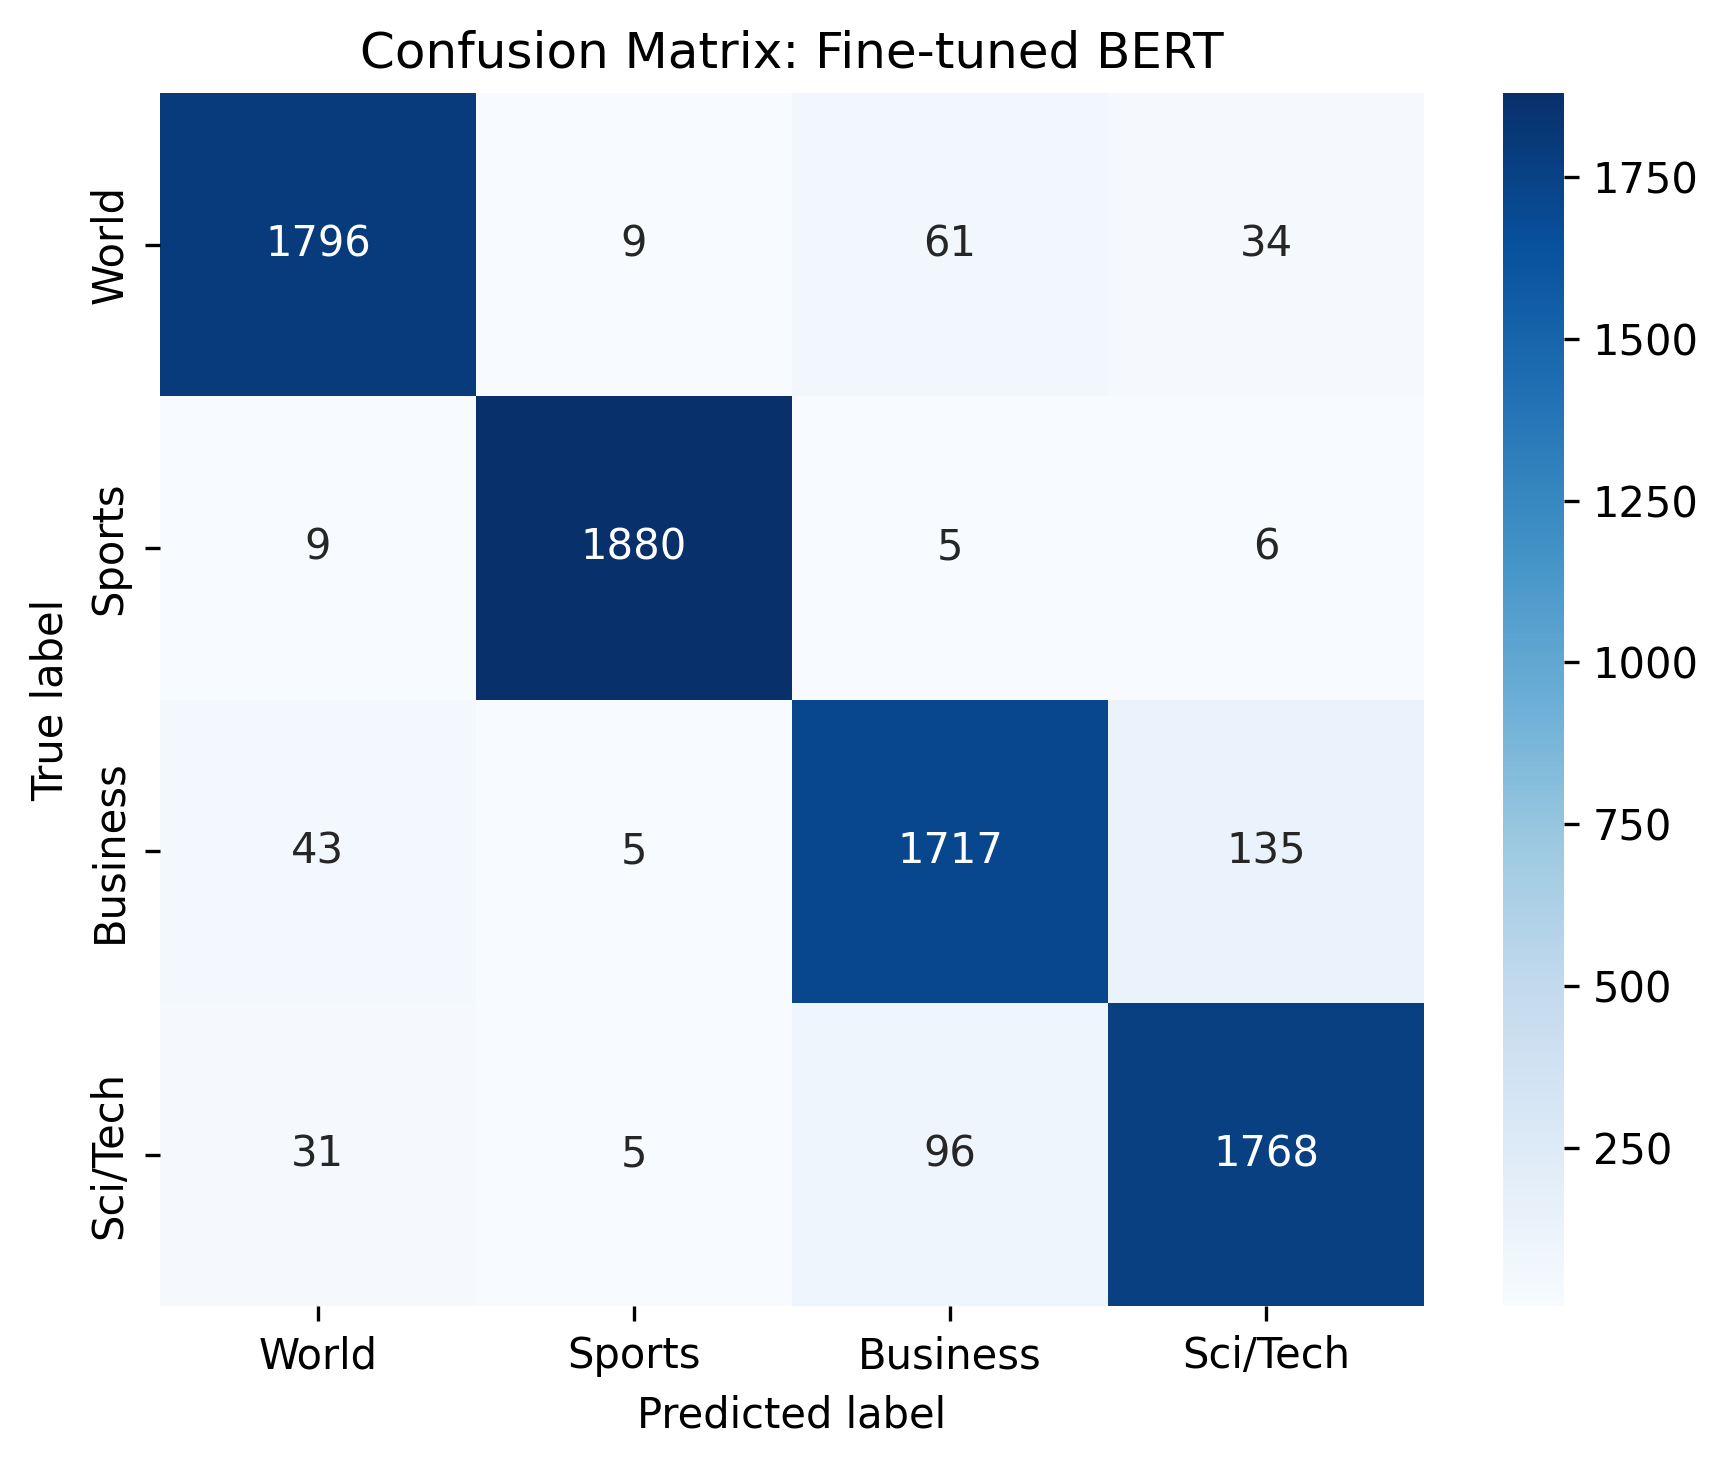

In [7]:
display(Image(filename=str(config.FIGURES_DIR / "bert_training_curve.png"), width=460))
display(Image(filename=str(config.FIGURES_DIR / "bert_confusion_matrix.png"), width=480))

## 3.5 Explaining BERT predictions with LIME

We explain the same test article as in the Naive Bayes notebook, which allows a direct comparison of the evidence each model relies on.

Article: Fears for T N pension after talks Unions representing workers at Turner Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.
True label: Business | predicted: Business (p = 0.998)
  Mogul                +0.0322
  firm                 +0.0295
  Unions               +0.0238
  pension              +0.0221
  workers              +0.0210
  Turner               +0.0151
  T                    +0.0123
  Federal              +0.0106
  Fears                +0.0106
  disappointed         -0.0104


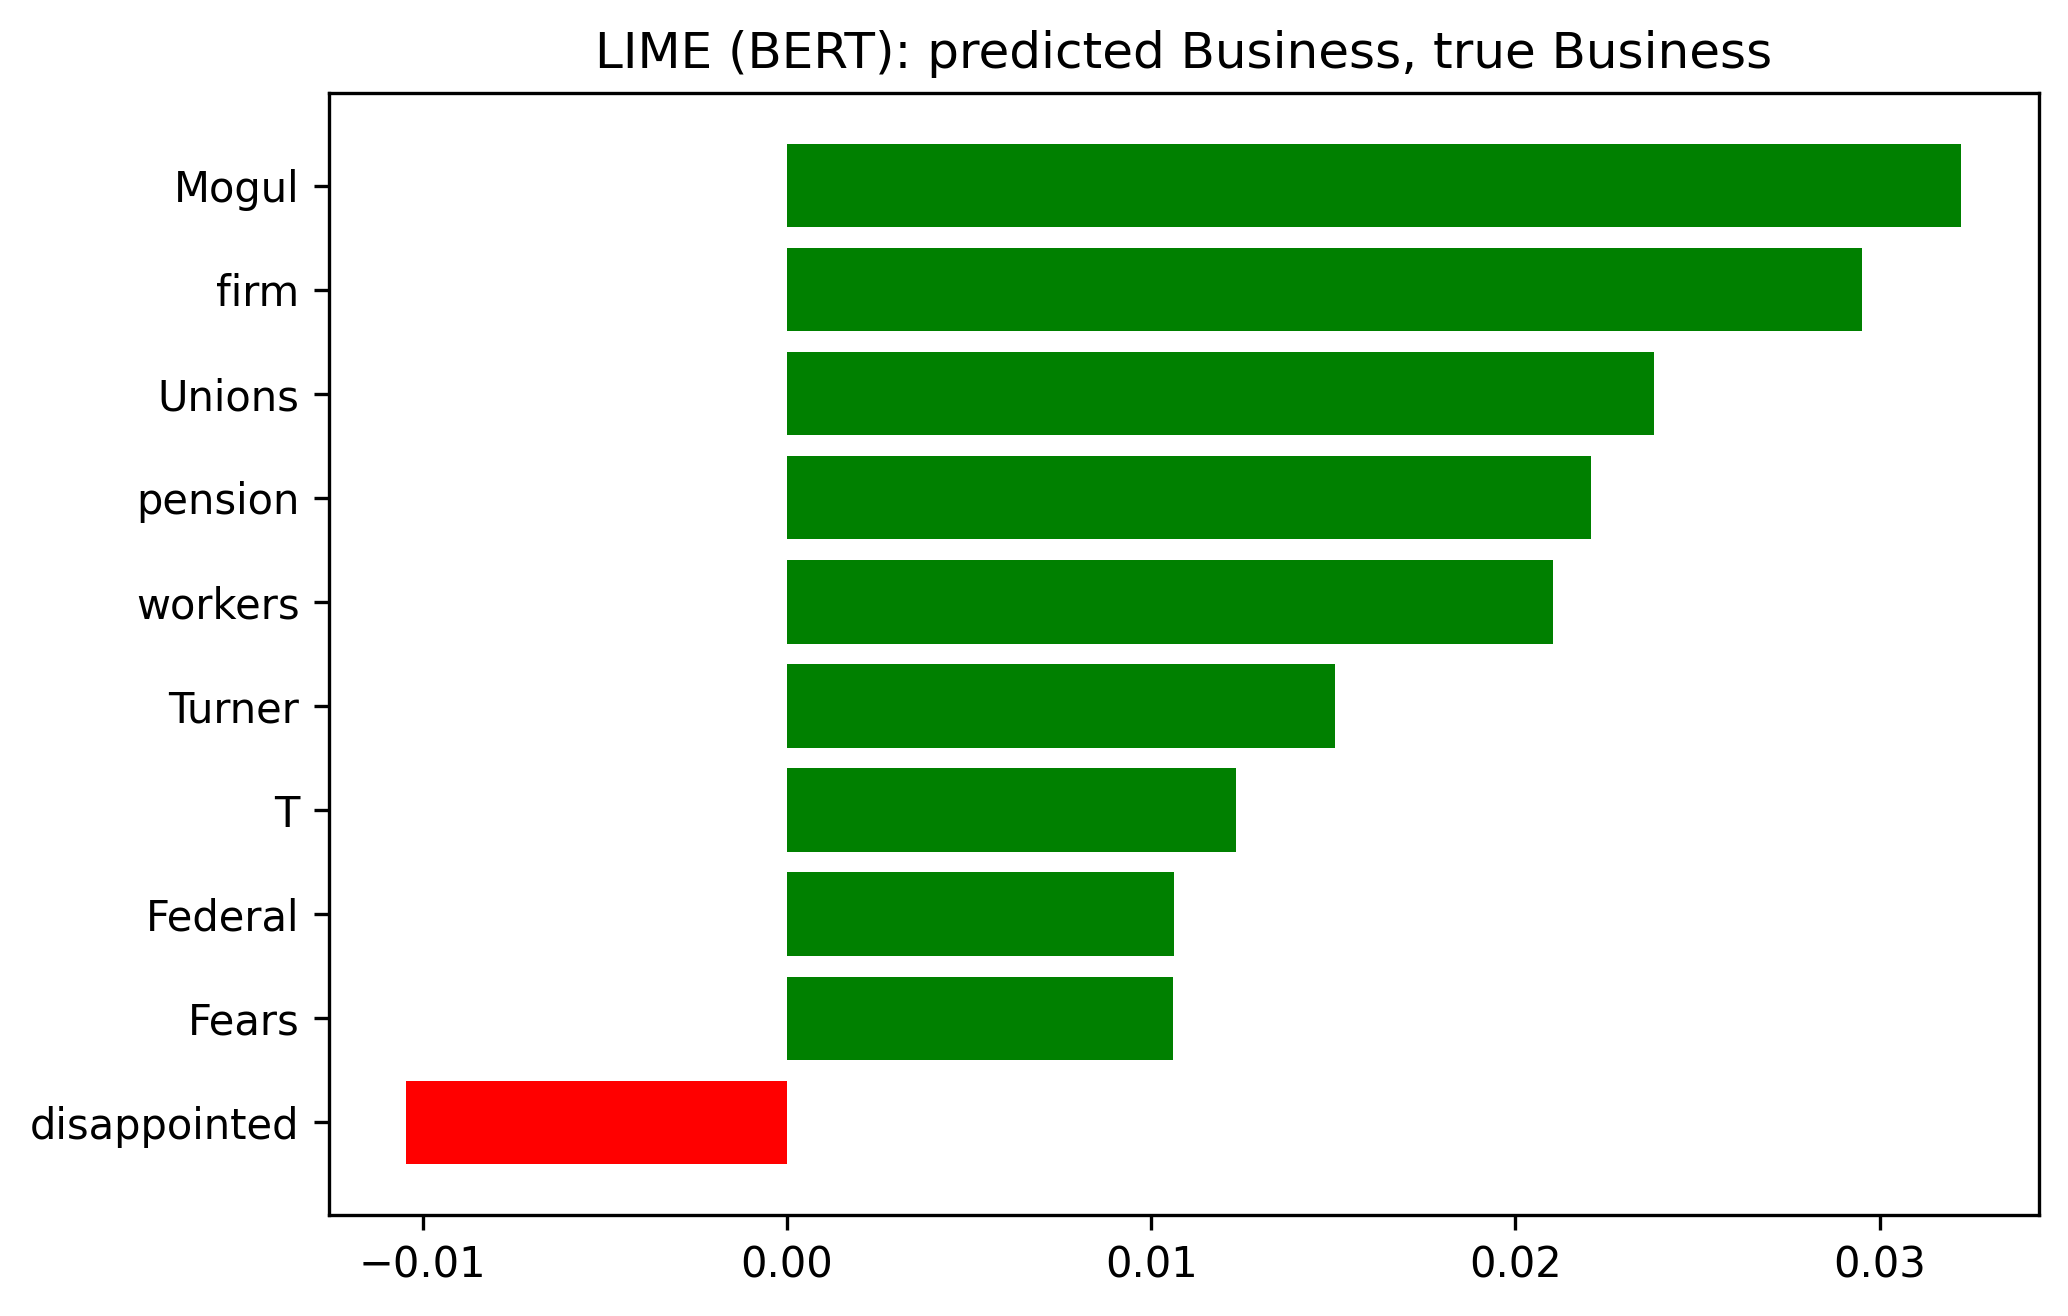

In [8]:
from src.explain_model import explain

exp = explain(model="bert", index=0)
display(Image(filename=str(config.FIGURES_DIR / "lime_bert_test0.png"), width=640))

The interactive version is written to `results/figures/lime_bert_test0.html`.

## 3.6 Export results

On Colab, the metrics and figures are packaged into `bert_results.zip` for download. The executed notebook itself can be saved with *File > Download > Download .ipynb*.

In [ ]:
if IN_COLAB:
    import shutil
    from google.colab import files

    export = Path("/content/bert_results")
    shutil.rmtree(export, ignore_errors=True)
    (export / "metrics").mkdir(parents=True)
    (export / "figures").mkdir(parents=True)
    for f in config.METRICS_DIR.glob("bert_*"):
        shutil.copy(f, export / "metrics")
    for f in list(config.FIGURES_DIR.glob("bert_*")) + list(config.FIGURES_DIR.glob("lime_bert_*")):
        shutil.copy(f, export / "figures")
    shutil.make_archive("/content/bert_results", "zip", export)
    files.download("/content/bert_results.zip")